# Matbench bandgap prediction: MAE optimisation

Composition-only experiments derived from my Lecture9 work in [Aron Walsh’s course](https://github.com/aronwalsh/MLforMaterials). Uses [Matbench’s official outer folds](https://github.com/materialsproject/matbench) and independent inner model selection. Previous exploration of this dataset is documented in the historical notebook; this is not a claim of previously unseen data.

All choices below are fixed before final evaluation. Test targets are never used for feature selection, imputation, fitting, or tuning. Rows rotate roles across outer folds; each prediction excludes its own test fold. Do not adapt this protocol after inspecting test scores.

## Experimental scope

The target is experimental bandgap in eV, inferred from composition alone. The workflow separates deterministic descriptor generation, fold-local preprocessing, inner-CV model selection, and outer-fold evaluation. The unit of comparison is the full selection procedure: each outer fold may select a different configuration. This is not a single model evaluated on five independent external datasets.

In [1]:
from pathlib import Path
import json, hashlib, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matbench.bench import MatbenchBenchmark
from matminer.featurizers.composition import ElementProperty, ElementFraction, Stoichiometry, ValenceOrbital
from elementembeddings.composition import composition_featuriser
from pymatgen.core import Composition
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import KFold, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

SEED = 42
OUT = Path('results/mae')
OUT.mkdir(parents=True, exist_ok=True)
# Use canonical task splits; do not replace them with a new random holdout.
mb = MatbenchBenchmark(autoload=False, subset=['matbench_expt_gap'])
task = next(iter(mb.tasks))
task.load()


2026-11-13 16:16:49 INFO     Initialized benchmark 'matbench_v0.1' with 1 tasks: 
['matbench_expt_gap']


2026-11-13 16:16:49 INFO     Loading dataset 'matbench_expt_gap'...


2026-11-13 16:16:50 INFO     Dataset 'matbench_expt_gap loaded.


## Composition representations

Feature lookup is deterministic and does not use targets. Learned imputation and constant-column removal are fitted within each training fold. Full Magpie statistics capture extrema and spread; element fractions and stoichiometry retain additional composition information.

| Representation | Information retained |
|---|---|
| `mean_variance` | Composition-weighted means and variances of Magpie elemental properties |
| `magpie` | The matminer Magpie preset: minimum, maximum, range, mean, average deviation, and mode |
| `magpie_composition` | Magpie statistics plus elemental fractions, stoichiometric descriptors, and valence-orbital summaries |

Descriptor lookup is independent of observed bandgaps, so it can be reused across inner folds. In contrast, imputation medians and the mask of nonconstant features are estimated by each fitted pipeline. No feature scaling is applied to these tree estimators.

### Search construction and selection objective

Training loss and selection metric serve different roles. Squared-error and absolute-error objectives produce different fitted models, but every candidate is ranked by mean validation MAE. The sign returned by scikit-learn's negative-MAE scorer is reversed before minimisation. Fixed seeds make the sampled search reproducible within the recorded software environment; they do not guarantee bitwise portability across platforms.

This initial search samples three configurations separately for each representation/loss pair: 18 candidates per outer fold and 270 inner fits overall. Because hyperparameters are not matched across representations, score differences cannot isolate the effect of representation alone. This motivates the subsequent controlled model-comparison notebook.

The protocol hash identifies the serialised seed, inner-fold count, and candidate list. It is a configuration fingerprint, not a checksum of the dataset, software environment, or trained models.

In [2]:
FEATURES = ['mean_variance', 'magpie', 'magpie_composition']
# Only composition-derived lookup and aggregation occurs here; no targets are consumed.
def features(inputs, kind):
    if kind == 'mean_variance':
        frame = pd.DataFrame({'composition': list(inputs)})
        values = composition_featuriser(frame, formula_column='composition', embedding='magpie', stats=['mean', 'variance'])
        return values.drop(columns='composition').to_numpy(dtype=float)
    featurizers = [ElementProperty.from_preset('magpie')]
    if kind == 'magpie_composition':
        featurizers += [ElementFraction(), Stoichiometry(), ValenceOrbital()]
    return np.asarray([[v for f in featurizers for v in f.featurize(Composition(s))] for s in inputs], dtype=float)

# Keep data-dependent preprocessing inside the estimator cloned by inner CV.
def pipeline(params):
    return make_pipeline(SimpleImputer(strategy='median', keep_empty_features=True),
                         VarianceThreshold(), XGBRegressor(random_state=SEED, n_jobs=1, **params))

# Sample the candidate list once, before any outer-fold selection or test scoring.
rng = np.random.default_rng(SEED)
candidates = []
for kind in FEATURES:
    for loss in ['reg:squarederror', 'reg:absoluteerror']:
        for _ in range(3):
            params = dict(objective=loss, max_depth=int(rng.integers(2,9)),
                learning_rate=float(np.exp(rng.uniform(np.log(.01),np.log(.2)))),
                n_estimators=int(rng.integers(200,801)), min_child_weight=int(rng.integers(1,21)),
                subsample=float(rng.uniform(.6,1)), colsample_bytree=float(rng.uniform(.6,1)),
                reg_alpha=float(10**rng.uniform(-4,1)), reg_lambda=float(10**rng.uniform(-2,2)))
            candidates.append(dict(features=kind, params=params))
protocol = dict(seed=SEED, inner_folds=3, candidates=candidates)
protocol_hash = hashlib.sha256(json.dumps(protocol, sort_keys=True).encode()).hexdigest()
print('Fixed protocol:', protocol_hash, '| Candidates:', len(candidates))


Fixed protocol: 4c750e83eba350c5e45c030f8b7ab381635b7eaed026e53e9943213a741fc633 | Candidates: 18


## Training-only smoke check

No test inputs or targets are accessed here.

This small fit checks descriptor generation and estimator compatibility using only an outer training portion. Its finite-prediction assertion is an execution check, not evidence of predictive performance. The smoke-check model is not reused in the search.

In [3]:
train_inputs, train_targets = task.get_train_and_val_data(task.folds[0])
a = features(train_inputs.iloc[:40], 'magpie_composition')
smoke = pipeline(dict(n_estimators=2, max_depth=2, objective='reg:absoluteerror'))
smoke.fit(a[:30], train_targets.iloc[:30])
assert np.isfinite(smoke.predict(a[30:])).all()
print('Training-only smoke check passed')


Training-only smoke check passed


/Users/nick/Code/materials-ml/MatBenchExperiments/.venv/lib/python3.12/site-packages/matminer/utils/data.py:326: UserWarning: MagpieData(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by the average of that value
                    over the available elements.
                    This avoids NaNs after featurization that are often replaced by
                    dataset-dependent averages.
  warnings.warn(f"{self.__class__.__name__}(impute_nan=False):\n" + IMPUTE_NAN_WARNING)
/Users/nick/Code/materials-ml/MatBenchExperiments/.venv/lib/python3.12/site-packages/matminer/featurizers/composition/orbital.py:115: UserWarning: ValenceOrbital(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
     

## Inner validation and independent outer-fold refits

The median baseline and original fixed XGBoost configuration are references. Select only by inner MAE; identical inner splits are used for every candidate. This quick search uses 270 candidate fits plus baselines and refits. It is not guaranteed to improve on previous results.

For each official outer split, candidates share the same three shuffled inner folds. `cross_val_score` clones and fits the entire pipeline separately on each inner training fold, including imputation and feature filtering. The median predictor and original fixed XGBoost configuration are reference scores; they are not eligible winners in `trials`.

`matrices` caches the three deterministic representations for the current outer training portion. `rows` records candidate validation results; `frozen` holds each selected configuration and its refitted model. Selection is independent for each outer fold, with the first candidate winning an exact tie. The winning pipeline is refitted on the full outer training portion before persistence.

Split assertions check disjointness and complete sample coverage. They are structural safeguards; correct separation also depends on keeping all fitting and selection inside the indicated training boundaries. Test IDs are used for coverage checks, not to access test targets.

Saved `.joblib` files contain fitted pipelines. `inner_validation.csv` records selection scores, and `protocol.json` records candidates and fold-specific choices. The selected inner MAE is optimistic after searching multiple candidates and should not be presented as an independent test estimate.


In [4]:
frozen = {}
rows = []
coverage = []
for fold in task.folds:
    inputs, y = task.get_train_and_val_data(fold)
    split = task.validation[task.folds_map[fold]]
    train_ids, test_ids = set(split.train), set(split.test)
    assert train_ids.isdisjoint(test_ids)
    coverage.extend(split.test)
    # Reuse identical inner splits for all candidates within this outer training portion.
    cv = list(KFold(3, shuffle=True, random_state=SEED).split(inputs))
    for tr, va in cv:
        assert set(tr).isdisjoint(va)
        assert len(tr) + len(va) == len(inputs)
    # Cache fixed descriptors, not fitted preprocessing or target-dependent feature selection.
    matrices = {kind: features(inputs, kind) for kind in FEATURES}
    for name, estimator in [('median', DummyRegressor(strategy='median')),
            ('original_xgb', pipeline(dict(n_estimators=100, max_depth=3, objective='reg:squarederror')))]:
        scores = -cross_val_score(estimator, matrices['mean_variance'], y, cv=cv,
                                  scoring='neg_mean_absolute_error', n_jobs=1)
        rows.append(dict(fold=fold, candidate=name, inner_mae=float(scores.mean())))
    trials = []
    for i, candidate in enumerate(candidates):
        scores = -cross_val_score(pipeline(candidate['params']), matrices[candidate['features']], y,
                                 cv=cv, scoring='neg_mean_absolute_error', n_jobs=1)
        score = float(scores.mean())
        assert np.isfinite(score)
        trials.append(score)
        rows.append(dict(fold=fold, candidate=i, inner_mae=score))
    # Select exclusively on inner MAE, then fit a fresh pipeline on all outer training data.
    winner = int(np.argmin(trials))
    choice = candidates[winner]
    model = pipeline(choice['params']).fit(matrices[choice['features']], y)
    frozen[fold] = dict(model=model, choice=choice, inner_mae=trials[winner],
                        columns=matrices[choice['features']].shape[1])
    joblib.dump(frozen[fold], OUT / f'fold_{fold}.joblib')
    print('Completed training fold', fold, '| selected inner MAE', trials[winner])
# Every canonical sample must appear in exactly one outer test fold.
assert len(coverage) == len(set(coverage)) == len(task.df)
assert set(coverage) == set(task.df.index)
pd.DataFrame(rows).to_csv(OUT / 'inner_validation.csv', index=False)
(OUT / 'protocol.json').write_text(json.dumps(dict(**protocol, sha256=protocol_hash,
    selections={str(f): v['choice'] for f,v in frozen.items()}), indent=2))
assert len(frozen) == 5
print('All five models frozen. No outer test scores have been inspected.')


Featurising compositions...


  0%|          | 0/3683 [00:00<?, ?it/s]

  6%|▋         | 238/3683 [00:00<00:01, 2372.72it/s]

 13%|█▎        | 477/3683 [00:00<00:01, 2382.48it/s]

 19%|█▉        | 717/3683 [00:00<00:01, 2386.69it/s]

 26%|██▌       | 960/3683 [00:00<00:01, 2400.61it/s]

... (106 outputs left out)

100%|██████████| 3684/3684 [00:00<00:00, 300829.68it/s]


/Users/nick/Code/materials-ml/MatBenchExperiments/.venv/lib/python3.12/site-packages/matminer/utils/data.py:326: UserWarning: MagpieData(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by the average of that value
                    over the available elements.
                    This avoids NaNs after featurization that are often replaced by
                    dataset-dependent averages.
  warnings.warn(f"{self.__class__.__name__}(impute_nan=False):\n" + IMPUTE_NAN_WARNING)


/Users/nick/Code/materials-ml/MatBenchExperiments/.venv/lib/python3.12/site-packages/matminer/featurizers/composition/orbital.py:115: UserWarning: ValenceOrbital(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by the average of that value
                    over the available elements.
                    This avoids NaNs after featurization that are often replaced by
                    dataset-dependent averages.
  warn(f"{self.__class__.__name__}(impute_nan=False):\n" + IMPUTE_NAN_WARNING)
/Users/nick/Code/materials-ml/MatBenchExperiments/.venv/lib/python3.12/site-packages/pymatgen/core/composition.py:1373: FutureWarning: gcd is deprecated, and will be removed on 2028-01-01
Use math.gcd instead.
  factor = abs(gcd(*(int(i) for i in sym_amt.values())))


Completed training fold 4 | selected inner MAE 0.43710033157600275
All five models frozen. No outer test scores have been inspected.


## Final evaluation — run after all models are frozen

This is the only section that scores outer test predictions. Do not change the method in response to these results. The leaderboard statistic is the unweighted mean of five test MAEs, not the inner tuning score.

At this boundary all five models have already been selected and refitted. Test descriptors are generated with the chosen representation and transformed by the saved pipeline without refitting. All predictions are collected before `task.record` computes scores against the benchmark targets internally. This avoids using earlier outer test scores to revise later fold models during the run.

The export contains sample-indexed predictions and per-fold parameters. `test_scores.csv` summarises outer scores; the headline statistic is the unweighted mean of five MAEs. `ddof=0` reports their population standard deviation, describing fold variability rather than a confidence interval. These public-dataset results follow prior exploration and should be interpreted as benchmark development, not untouched external confirmation.


In [5]:
test_predictions = {}
for fold in task.folds:
    entry = frozen[fold]
    # Targets remain withheld; predict using this fold’s already-selected pipeline.
    inputs = task.get_test_data(fold, include_target=False)
    X = features(inputs, entry['choice']['features'])
    assert X.shape[1] == entry['columns']
    pred = entry['model'].predict(X)
    assert len(pred) == len(inputs) and np.isfinite(pred).all()
    test_predictions[fold] = pred
# Only after every prediction is fixed, reveal scores.
for fold in task.folds:
    task.record(fold, test_predictions[fold], params=frozen[fold]['choice'])
mb.to_file(str(OUT / 'matbench_results.json.gz'))
summary = pd.DataFrame([dict(fold=f, **task.results[task.folds_map[f]].scores) for f in task.folds])
display(summary)
print('Test MAE mean:', summary.mae.mean(), 'eV; population SD:', summary.mae.std(ddof=0))
summary.to_csv(OUT / 'test_scores.csv', index=False)


/Users/nick/Code/materials-ml/MatBenchExperiments/.venv/lib/python3.12/site-packages/matminer/utils/data.py:326: UserWarning: MagpieData(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by the average of that value
                    over the available elements.
                    This avoids NaNs after featurization that are often replaced by
                    dataset-dependent averages.
  warnings.warn(f"{self.__class__.__name__}(impute_nan=False):\n" + IMPUTE_NAN_WARNING)


/Users/nick/Code/materials-ml/MatBenchExperiments/.venv/lib/python3.12/site-packages/matminer/utils/data.py:326: UserWarning: MagpieData(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by the average of that value
                    over the available elements.
                    This avoids NaNs after featurization that are often replaced by
                    dataset-dependent averages.
  warnings.warn(f"{self.__class__.__name__}(impute_nan=False):\n" + IMPUTE_NAN_WARNING)


/Users/nick/Code/materials-ml/MatBenchExperiments/.venv/lib/python3.12/site-packages/matminer/utils/data.py:326: UserWarning: MagpieData(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by the average of that value
                    over the available elements.
                    This avoids NaNs after featurization that are often replaced by
                    dataset-dependent averages.
  warnings.warn(f"{self.__class__.__name__}(impute_nan=False):\n" + IMPUTE_NAN_WARNING)


/Users/nick/Code/materials-ml/MatBenchExperiments/.venv/lib/python3.12/site-packages/matminer/utils/data.py:326: UserWarning: MagpieData(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by the average of that value
                    over the available elements.
                    This avoids NaNs after featurization that are often replaced by
                    dataset-dependent averages.
  warnings.warn(f"{self.__class__.__name__}(impute_nan=False):\n" + IMPUTE_NAN_WARNING)


/Users/nick/Code/materials-ml/MatBenchExperiments/.venv/lib/python3.12/site-packages/matminer/utils/data.py:326: UserWarning: MagpieData(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by the average of that value
                    over the available elements.
                    This avoids NaNs after featurization that are often replaced by
                    dataset-dependent averages.
  warnings.warn(f"{self.__class__.__name__}(impute_nan=False):\n" + IMPUTE_NAN_WARNING)


2026-11-13 16:20:46 INFO     Recorded fold matbench_expt_gap-0 successfully.


... (3 outputs left out)

2026-11-13 16:20:46 INFO     Recorded fold matbench_expt_gap-4 successfully.


2026-11-13 16:20:46 INFO     Successfully wrote MatbenchBenchmark to file 'results/mae/matbench_results.json.gz'.


,fold,mae,rmse,mape,max_error
0,0,0.391730,0.750813,0.316992,5.378967
1,1,0.394291,0.716404,0.281492,5.122038
2,2,0.449277,0.910675,0.383865,9.776572
3,3,0.402028,0.768717,0.356971,4.994853
4,4,0.404590,0.772088,0.381746,6.425998


Test MAE mean: 0.40838324537233783 eV; population SD: 0.020990405694209062


## Test prediction diagnostics

The parity plot pools out-of-fold test predictions: every point was predicted by a model that excluded its outer test fold from training and tuning. Agreement lies along the identity line. Residuals are predicted minus observed gap, so positive values indicate overprediction. Patterns across gap values can reveal systematic error; isolated large residuals affect RMSE more strongly than MAE. These plots are post-evaluation diagnostics and do not feed back into this run's selection procedure.

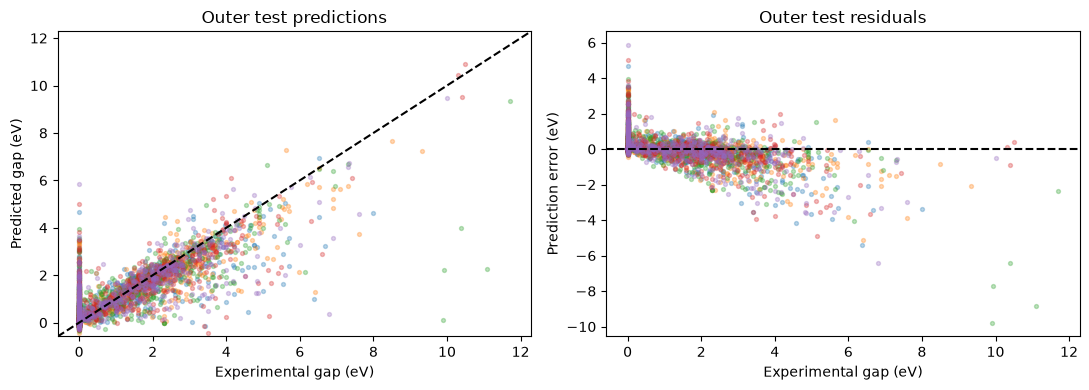

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11,4))
for fold in task.folds:
    _, truth = task.get_test_data(fold, include_target=True)
    pred = test_predictions[fold]
    axes[0].scatter(truth, pred, s=8, alpha=.3)
    axes[1].scatter(truth, pred-np.asarray(truth), s=8, alpha=.3)
lo, hi = axes[0].get_xlim()
axes[0].plot([lo,hi],[lo,hi], 'k--')
axes[0].set(xlim=(lo,hi), ylim=(lo,hi), xlabel='Experimental gap (eV)', ylabel='Predicted gap (eV)', title='Outer test predictions')
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set(xlabel='Experimental gap (eV)', ylabel='Prediction error (eV)', title='Outer test residuals')
plt.tight_layout()
